#Import Libraries

In [ ]:
!pip install -q optuna

In [ ]:
import time
import numpy as np
import polars as pl
import polars.selectors as cs
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
import seaborn as sns
import kagglehub
import gc
import re

from sklearn.metrics import (accuracy_score, roc_auc_score, precision_score, recall_score,
                             f1_score, confusion_matrix, ConfusionMatrixDisplay,
                             precision_recall_curve, roc_curve, classification_report)

from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder, OrdinalEncoder, FunctionTransformer
from sklearn.model_selection import GridSearchCV, RandomizedSearchCV, TimeSeriesSplit
import optuna
optuna.logging.set_verbosity(optuna.logging.WARNING)

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
import lightgbm as lgb


#Problem Definition

Vấn đề: Home Credit cho vay những người có ít hoặc không có lịch sử tín dụng. Ngân hàng cần ước lượng khả năng vỡ nợ của từng hồ sơ để quyết định duyệt hay từ chối.


Bài toán: Phân loại nhị phân. Mỗi dòng là một hồ sơ vay (case_id); nhãn target = 1 nếu vỡ nợ, 0 nếu không. Mô hình trả về xác suất vỡ nợ, dùng để xếp hạng rủi ro.


Đặc điểm dữ liệu:

Dữ liệu theo thời gian (WEEK_NUM), mô hình phải dự đoán cho khách hàng tương lai.


Phương pháp:
- Logistic Regression: mô hình tuyến tính kinh điển trong chấm điểm tín dụng, dễ giải thích. Dùng làm baseline để đánh giá các mô hình phức tạp hơn có cần thiết hay không.


- Decision Tree: trực quan, ra quy tắc dạng “nếu… thì…”, nhưng dễ overfit.


- Random Forest (bagging): nhiều cây học song song trên các mẫu ngẫu nhiên rồi lấy trung bình, giúp giảm overfit.


- LightGBM (boosting): nhiều cây học nối tiếp, mỗi cây sửa lỗi của các cây trước. Thường cho kết quả tốt nhất trên dữ liệu bảng; tự xử lý giá trị thiếu và biến phân loại; huấn luyện nhanh nhờ kỹ thuật histogram.

Cả 4 mô hình được đánh giá trên cùng tập Test và cùng bộ metric.


Đánh giá:

Metric chính: ROC-AUC / Gini.
Độ ổn định: Gini Stability (metric chính thức của cuộc thi).
Ý nghĩa nghiệp vụ: Precision, Recall, F1.

#Loading Data

In [ ]:
kagglehub.login()

Kaggle credentials set.
Kaggle credentials successfully validated.


In [ ]:
train_base = pl.read_csv(kagglehub.competition_download("home-credit-credit-risk-model-stability", path="csv_files/train/train_base.csv"))
train_static_0_0 = pl.read_csv(kagglehub.competition_download("home-credit-credit-risk-model-stability", path="csv_files/train/train_static_0_0.csv"))
train_static_0_1 = pl.read_csv(kagglehub.competition_download("home-credit-credit-risk-model-stability", path="csv_files/train/train_static_0_1.csv"))
train_static_cb_0 = pl.read_csv(kagglehub.competition_download("home-credit-credit-risk-model-stability", path="csv_files/train/train_static_cb_0.csv"))

100%|██████████| 3.67M/3.67M [00:01<00:00, 2.94MB/s]

Extracting zip of train_base.csv...


100%|██████████| 131M/131M [00:06<00:00, 20.0MB/s]

Extracting zip of train_static_0_0.csv...


100%|██████████| 79.5M/79.5M [00:04<00:00, 18.1MB/s]

Extracting zip of train_static_0_1.csv...


100%|██████████| 35.2M/35.2M [00:03<00:00, 10.7MB/s]

Extracting zip of train_static_cb_0.csv...


In [ ]:
train_static = pl.concat([train_static_0_0, train_static_0_1], how = "vertical_relaxed")

df = (train_base
      .join(train_static, on="case_id", how="left")
      .join(train_static_cb_0, on="case_id", how="left")
      .sort(["WEEK_NUM", "case_id"]))

#Data Understanding

In [ ]:
print(df.shape)

(1526659, 224)


In [ ]:
print(df.head())

shape: (5, 224)
┌─────────┬────────────┬────────┬──────────┬───┬────────────┬────────────┬────────────┬────────────┐
│ case_id ┆ date_decis ┆ MONTH  ┆ WEEK_NUM ┆ … ┆ riskassesm ┆ riskassesm ┆ secondquar ┆ thirdquart │
│ ---     ┆ ion        ┆ ---    ┆ ---      ┆   ┆ ent_302T   ┆ ent_940T   ┆ ter_766L   ┆ er_1082L   │
│ i64     ┆ ---        ┆ i64    ┆ i64      ┆   ┆ ---        ┆ ---        ┆ ---        ┆ ---        │
│         ┆ str        ┆        ┆          ┆   ┆ str        ┆ f64        ┆ f64        ┆ f64        │
╞═════════╪════════════╪════════╪══════════╪═══╪════════════╪════════════╪════════════╪════════════╡
│ 0       ┆ 2019-01-03 ┆ 201901 ┆ 0        ┆ … ┆ null       ┆ null       ┆ null       ┆ null       │
│ 1       ┆ 2019-01-03 ┆ 201901 ┆ 0        ┆ … ┆ null       ┆ null       ┆ null       ┆ null       │
│ 2       ┆ 2019-01-04 ┆ 201901 ┆ 0        ┆ … ┆ null       ┆ null       ┆ null       ┆ null       │
│ 3       ┆ 2019-01-03 ┆ 201901 ┆ 0        ┆ … ┆ null       ┆ null       ┆ 

In [ ]:
print(df.describe())

shape: (9, 225)
┌───────────┬───────────┬───────────┬───────────┬───┬───────────┬───────────┬───────────┬──────────┐
│ statistic ┆ case_id   ┆ date_deci ┆ MONTH     ┆ … ┆ riskasses ┆ riskasses ┆ secondqua ┆ thirdqua │
│ ---       ┆ ---       ┆ sion      ┆ ---       ┆   ┆ ment_302T ┆ ment_940T ┆ rter_766L ┆ rter_108 │
│ str       ┆ f64       ┆ ---       ┆ f64       ┆   ┆ ---       ┆ ---       ┆ ---       ┆ 2L       │
│           ┆           ┆ str       ┆           ┆   ┆ str       ┆ f64       ┆ f64       ┆ ---      │
│           ┆           ┆           ┆           ┆   ┆           ┆           ┆           ┆ f64      │
╞═══════════╪═══════════╪═══════════╪═══════════╪═══╪═══════════╪═══════════╪═══════════╪══════════╡
│ count     ┆ 1.526659e ┆ 1526659   ┆ 1.526659e ┆ … ┆ 53559     ┆ 53560.0   ┆ 1.385691e ┆ 1.385691 │
│           ┆ 6         ┆           ┆ 6         ┆   ┆           ┆           ┆ 6         ┆ e6       │
│ null_coun ┆ 0.0       ┆ 0         ┆ 0.0       ┆ … ┆ 1473100   ┆ 1.473099e

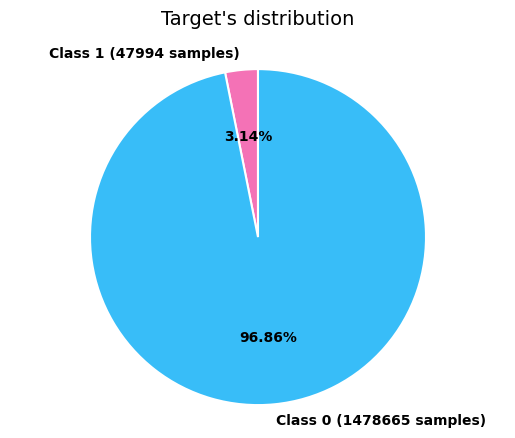

In [ ]:
target_counts = df['target'].value_counts()
custom_colors = ['#F472B6', '#38BDF8']

plt.pie(target_counts['count'],
        labels=[f'Class {idx} ({val} samples)' for idx, val in target_counts.iter_rows()],
        autopct='%1.2f%%',
        startangle=90,
        colors=custom_colors,
        wedgeprops={'edgecolor': 'white', 'linewidth': 1.5},
        textprops={'fontsize': 10, 'weight': 'bold'})

plt.title("Target's distribution", fontsize=14, pad=20)
plt.axis('equal')
plt.show()

In [ ]:
null_count = df.null_count()
null_count.select([c for c in null_count.columns if null_count[c][0] > 0]).transpose(include_header=True)

column,column_0
str,u32
"""actualdpdtolerance_344P""",418178
"""amtinstpaidbefduel24m_4187115A""",561124
"""annuitynextmonth_57A""",4
"""avgdbddpdlast24m_3658932P""",613202
"""avgdbddpdlast3m_4187120P""",948244
…,…
"""responsedate_4917613D""",1301747
"""riskassesment_302T""",1473100
"""riskassesment_940T""",1473099


In [ ]:
cols_null_50 = [c for c in null_count.columns if null_count[c][0] > 0.5 * df.height]
null_count.select(cols_null_50).transpose(include_header=True)

column,column_0
str,u32
"""avgdbddpdlast3m_4187120P""",948244
"""avgdbdtollast24m_4525197P""",972827
"""avglnamtstart24m_4525187A""",1364150
"""avgoutstandbalancel6m_4187114A""",841181
"""avgpmtlast12m_4525200A""",1026987
…,…
"""responsedate_1012D""",806659
"""responsedate_4527233D""",866332
"""responsedate_4917613D""",1301747


In [ ]:
df["case_id"].n_unique() == df.height

True

In [ ]:
print("Number of Weeks:", df["WEEK_NUM"].n_unique())
print("From", df["WEEK_NUM"].min(), "to", df["WEEK_NUM"].max())

Number of Weeks: 92
From 0 to 91


In [ ]:
type_groups = {
    "Numeric": df.select(cs.numeric()).columns,
    "String": df.select(cs.string()).columns,
    "Boolean": df.select(cs.boolean()).columns,
    "Datetime": df.select(cs.temporal()).columns,
}

summary = pl.DataFrame({
    "Data Type": list(type_groups.keys()),
    "Number of Features": [len(v) for v in type_groups.values()],
})
print(f"Total: {df.width} columns")
summary

Total: 224 columns


Data Type,Number of Features
str,i64
"""Numeric""",134
"""String""",85
"""Boolean""",5
"""Datetime""",0


In [ ]:
META = ["case_id", "date_decision", "MONTH", "WEEK_NUM", "target"]
suffix_meaning = {"A": "Amount", "D": "Date", "M": "Masking categories",
                  "P": "Days past due", "L": "Unspecified Transform", "T": "Unspecified Transform"}

feat_cols = [c for c in df.columns if c not in META]
(pl.DataFrame({"End_with": [c[-1] for c in feat_cols]})
   .group_by("End_with").agg(pl.len().alias("num_of_cols"))
   .with_columns(pl.col("End_with").replace(suffix_meaning).alias("Meaning"))
   .sort("num_of_cols", descending=True))

End_with,num_of_cols,Meaning
str,u32,str
"""L""",123,"""Unspecified Transform"""
"""A""",35,"""Amount"""
"""D""",24,"""Date"""
"""P""",22,"""Days past due"""
"""M""",13,"""Masking categories"""
"""T""",2,"""Unspecified Transform"""


#Data Splitting

In [ ]:
# SPLIT DATASET INTO TRAIN/ VALID/ TEST

weeks = np.sort(df["WEEK_NUM"].unique().to_numpy())
n_weeks = len(weeks)

train_weeks = weeks[: int(n_weeks * 0.70)].tolist()
valid_weeks = weeks[int(n_weeks * 0.70): int(n_weeks * 0.85)].tolist()
test_weeks  = weeks[int(n_weeks * 0.85):].tolist()

train_df = df.filter(pl.col("WEEK_NUM").is_in(train_weeks))
valid_df = df.filter(pl.col("WEEK_NUM").is_in(valid_weeks))
test_df  = df.filter(pl.col("WEEK_NUM").is_in(test_weeks))

In [ ]:
sets = {"Train": (train_df, train_weeks), "Validation": (valid_df, valid_weeks), "Test": (test_df, test_weeks)}
split_summary = pl.DataFrame({
    "Set":             list(sets),
    "Week":            [f"{min(w)} – {max(w)}" for _, w in sets.values()],
    "Num_of_week":         [len(w) for _, w in sets.values()],
    "Sample_size":        [d.height for d, _ in sets.values()],
    "Percentage of population":      [round(d.height / df.height * 100, 1) for d, _ in sets.values()],
    "Num_of_default":        [int(d["target"].sum()) for d, _ in sets.values()],
    "Default_ratio (%)": [round(d["target"].mean() * 100, 2) for d, _ in sets.values()],
})
split_summary

Set,Week,Num_of_week,Sample_size,Percentage of population,Num_of_default,Default_ratio (%)
str,str,i64,i64,f64,i64,f64
"""Train""","""0 – 63""",64,1282082,84.0,42524,3.32
"""Validation""","""64 – 77""",14,92870,6.1,2255,2.43
"""Test""","""78 – 91""",14,151707,9.9,3215,2.12


#Data Cleaning

In [ ]:
def ram_gb(*dfs):
    return round(sum(d.estimated_size("gb") for d in dfs), 2)

print("Original df RAM:", ram_gb(df), "GB")


for name in ["df", "train_base", "train_static", "train_static_0_0",
             "train_static_0_1", "train_static_cb_0"]:
    globals().pop(name, None)

%reset -f out
gc.collect()

print("After cleaning:", ram_gb(train_df, valid_df, test_df), "GB")

Original df RAM: 1.95 GB
Flushing output cache (6 entries)
After cleaning: 1.95 GB


In [ ]:
DATE_FMT = "%Y-%m-%d"

def build_type_plan(data):
    plan = {}
    for c, t in data.schema.items():
        if c in ("case_id", "MONTH", "WEEK_NUM", "target"):
            continue
        if c == "date_decision" or c.endswith("D"):
            plan[c] = "date"
        elif c == "riskassesment_302T":
            plan[c] = "range_pct"
        elif c.endswith("M"):
            plan[c] = "cat"
        elif c.endswith(("A", "P")):
            plan[c] = "num"
        elif t == pl.Boolean:
            plan[c] = "bool"
        elif t == pl.String:
            s = data.get_column(c).drop_nulls()
            vals = set(s.unique().to_list()) if s.n_unique() <= 2 else set()
            if vals and vals <= {"True", "False", "true", "false"}:
                plan[c] = "bool"
            elif s.len() > 0 and s.cast(pl.Float64, strict=False).null_count() == 0:
                plan[c] = "num"
            else:
                plan[c] = "cat"
            del s
        else:
            plan[c] = "num"
    return plan

def type_expr(c, kind):
    col = pl.col(c)
    if kind == "date":
        return col.cast(pl.String).str.to_date(DATE_FMT, strict=False).alias(c)
    if kind == "num":
        return col.cast(pl.Float32, strict=False).alias(c)
    if kind == "bool":
        s = col.cast(pl.String).str.to_lowercase()
        return (pl.when(s == "true").then(1).when(s == "false").then(0)
                  .otherwise(None).cast(pl.Int8).alias(c))
    if kind == "range_pct":
        s = col.cast(pl.String)
        lo = s.str.extract(r"([\d.]+)%\s*-", 1).cast(pl.Float32, strict=False)
        hi = s.str.extract(r"-\s*([\d.]+)%", 1).cast(pl.Float32, strict=False)
        return ((lo + hi) / 2).alias(c)
    return col.cast(pl.String).cast(pl.Categorical).alias(c)

def apply_type_plan(data, plan, batch_size=30):
    schema = data.schema
    todo = [(c, k) for c, k in plan.items()
            if c in schema
            and not (k == "cat" and schema[c] == pl.Categorical)
            and not (k == "num" and schema[c] == pl.Float32)]
    for i in range(0, len(todo), batch_size):
        data = data.with_columns([type_expr(c, k) for c, k in todo[i:i + batch_size]])
        gc.collect()
    return data


TYPE_PLAN = build_type_plan(train_df)

train_df = apply_type_plan(train_df, TYPE_PLAN); gc.collect()
valid_df = apply_type_plan(valid_df, TYPE_PLAN); gc.collect()
test_df  = apply_type_plan(test_df,  TYPE_PLAN); gc.collect()

print("Plan:", pl.Series(list(TYPE_PLAN.values())).value_counts().sort("count", descending=True).rows())
print("RAM after converting dtype:", ram_gb(train_df, valid_df, test_df), "GB")

Plan: [('num', 162), ('cat', 27), ('date', 25), ('bool', 5), ('range_pct', 1)]
RAM after converting dtype: 1.31 GB


In [ ]:
# REMOVE FEATURES WITH CONSTANT VALUES & MISSING VALUES

MISSING_THRESHOLD = 0.75

feat_cols = [c for c in train_df.columns if c not in META]
miss_ratio = (train_df.select(pl.col(feat_cols).null_count() / train_df.height)
                      .row(0, named=True))
high_missing = [c for c, r in miss_ratio.items() if r > MISSING_THRESHOLD]

kept = [c for c in feat_cols if c not in high_missing]
n_uniq = train_df.select([pl.col(c).drop_nulls().n_unique().alias(c) for c in kept]).row(0, named=True)
constant_cols = [c for c in kept if n_uniq[c] <= 1]

COLS_TO_DROP = high_missing + constant_cols
train_df = train_df.drop(COLS_TO_DROP)
valid_df = valid_df.drop(COLS_TO_DROP)
test_df  = test_df.drop(COLS_TO_DROP)

print(f"Before: {len(feat_cols)} features")
print(f"Remove {len(high_missing)} columns > {MISSING_THRESHOLD:.0%} missing values and {len(constant_cols)} constant columns")
print(f"After: {len([c for c in train_df.columns if c not in META])} features")

Before: 219 features
Remove 49 columns > 75% missing values and 11 constant columns
After: 159 features


#Feature Engineering

In [ ]:
# FEATURE ENGINEERING

def safe_ratio(num, den, min_den=0):
    if num not in COLS or den not in COLS:
        return None
    return (pl.when(pl.col(den).is_not_null() &(pl.col(den) > min_den))
        .then(pl.col(num) / pl.col(den))
        .otherwise(None)
    )

def safe_diff(a, b):
    if a not in COLS or b not in COLS:
        return None
    return pl.col(a) - pl.col(b)

def feature_engineering(data):
    global COLS
    COLS = set(data.columns)
    raw = [c for c in data.columns if c not in META]

    # 1. MISSINGNESS FEATURES
    data = data.with_columns([
        pl.sum_horizontal([
            pl.col(c).is_null().cast(pl.Int8)
            for c in raw
        ]).alias("n_missing"),

        pl.mean_horizontal([
            pl.col(c).is_null().cast(pl.Float32)
            for c in raw
        ]).alias("missing_ratio")
    ])


    # 2. AGE
    birth_cols = [c for c in ["dateofbirth_337D", "birthdate_574D", "birthdate_87D", "birth_259D", "dateofbirth_342D"] if c in COLS]
    birth_date = pl.coalesce([pl.col(c) for c in birth_cols])
    age = ((pl.col("date_decision") - birth_date).dt.total_days() / 365.25)
    data = data.with_columns(pl.when(age.is_between(18, 100)).then(age).otherwise(None).cast(pl.Float32).alias("age_years"))


    # 3. AFFORDABILITY FEATURES
    ratio_features = {
        "credit_to_income": ("credamount_770A", "maininc_215A"),
        "annuity_to_income": ("annuity_780A", "maininc_215A"),
        "debt_to_income": ("totaldebt_9A", "maininc_215A"),
        "other_income_ratio": ("lastotherinc_902A", "maininc_215A"),
        "monthly_installment_to_income": ("monthlyinstlamount_332A", "maininc_215A"),
        "installment_to_income": ("totinstallast1m_4525188A", "maininc_215A"),
        "downpayment_to_price": ("downpmt_116A", "price_1097A"),
        "downpayment_to_credit": ("downpmt_116A", "credamount_770A"),
        "annuity_to_credit": ("annuity_780A", "credamount_770A"),
        "previous_annuity_to_current_income": ("annuity_853A", "maininc_215A"),
        "previous_loan_to_income": ("avglnamtstart24m_4525187A", "maininc_215A"),
        "tax_payment_to_income": ("pmtamount_36A", "maininc_215A")
    }

    new_features = []

    for name, (num, den) in ratio_features.items():
        expr = safe_ratio(num, den)
        if expr is not None:
            new_features.append(expr.clip(-100, 100).cast(pl.Float32).alias(name))


    # 4. CREDIT UTILIZATION AND DEBT BURDEN
    ratio_features = {
        "outstanding_to_credit": ("totaloutstanddebtvalue_39A", "totalamount_996A"),
        "overdue_to_debt": ("totaldebtoverduevalue_178A", "totaldebt_9A"),
        "overdue_to_outstanding": ("totaldebtoverduevalue_178A", "totaloutstanddebtvalue_39A"),
        "active_overdue_ratio": ("overdueamount_659A", "outstandingamount_362A"),
        "max_overdue_ratio": ("overdueamountmax_155A", "outstandingamount_362A"),
        "pending_payment_ratio": ("pmtnumpending_403L", "numberofinstls_320L"),
        "outstanding_installment_ratio": ("numberofoutstandinstls_59L", "numberofinstls_320L"),
        "overdue_installment_ratio": ("numberofoverdueinstlmax_1039L", "numberofinstls_320L"),
        "active_credit_to_total_credit": ("totalamount_996A", "totalamount_6A")
    }

    for name, (num, den) in ratio_features.items():
        expr = safe_ratio(num, den)

        if expr is not None:
            new_features.append(expr.clip(-100, 100).cast(pl.Float32).alias(name)
            )


    # 5. PAYMENT BEHAVIOR
    late_features = [c for c in [
            "pctinstlsallpaidlate1d_3546856L",
            "pctinstlsallpaidlate4d_3546849L",
            "pctinstlsallpaidlate6d_3546844L",
            "pctinstlsallpaidlat10d_839L"
        ]if c in COLS]

    new_features.extend([
        pl.max_horizontal([pl.col(c).cast(pl.Float32)for c in late_features]).alias("max_late_payment_rate"),
        pl.mean_horizontal([pl.col(c).cast(pl.Float32)for c in late_features]).alias("avg_late_payment_rate")
    ])

    early_features = [c for c in ["pctinstlsallpaidearl3d_427L"]if c in COLS]
    new_features.append(pl.max_horizontal([pl.col(c).cast(pl.Float32)for c in early_features]).alias("early_payment_rate"))


    # 6. DPD RISK FEATURES
    dpd_features = [c for c in [
            "actualdpd_943P",
            "maxdpdlast24m_143P",
            "dpdmax_139P",
            "dpdmax_851P",
            "pmtdaysoverdue_1135P",
            "pmts_dpd_1073P",
            "pmts_dpd_303P"
        ]if c in COLS
    ]

    new_features.extend([
        pl.max_horizontal([
            pl.col(c).cast(pl.Float32)
            for c in dpd_features
        ]).alias("max_dpd_all"),

        pl.mean_horizontal([
            pl.col(c).cast(pl.Float32)
            for c in dpd_features
        ]).alias("avg_dpd_all")
    ])

    if "maxdpdlast24m_143P" in COLS:
        new_features.extend([
            (pl.col("maxdpdlast24m_143P") > 0).cast(pl.Float32).alias("has_dpd_24m"),
            (pl.col("maxdpdlast24m_143P") >= 30).cast(pl.Float32).alias("has_dpd30_24m"),
            (pl.col("maxdpdlast24m_143P") >= 60).cast(pl.Float32).alias("has_dpd60_24m"),
            (pl.col("maxdpdlast24m_143P") >= 90).cast(pl.Float32).alias("has_dpd90_24m")
        ])


    # 7. RECENT VS LONG-TERM PAYMENT BEHAVIOR
    new_features.append(
        (pl.col("avgmaxdpdlast9m_3716943P")- pl.col("avgdpdtolclosure24_3658938P")).cast(pl.Float32).alias("recent_dpd_change"))
    new_features.append(
        (pl.col("avgdbddpdlast3m_4187120P")- pl.col("avgdbddpdlast24m_3658932P")).cast(pl.Float32).alias("recent_payment_behavior_change"))


    # 8. APPLICATION / REJECTION BEHAVIOR

    reject_cols = [c for c in ["forweek_601L","formonth_118L","forquarter_462L","foryear_618L","for3years_128L","numrejects9m_859L"] if c in COLS]

    new_features.extend([
        pl.sum_horizontal([pl.col(c).cast(pl.Float32)for c in reject_cols]).alias("total_rejections"),
        pl.max_horizontal([pl.col(c).cast(pl.Float32)for c in reject_cols]).alias("max_rejections_period")
    ])


    # 9. CREDIT HISTORY

    contract_cols = [
        c for c in ["numberofcontrsvalue_258L","pmtnum_254L","pmtnum_8L","numberofinstls_320L","numberofinstls_810L"] if c in COLS]

    new_features.append(pl.sum_horizontal([pl.col(c).cast(pl.Float32)for c in contract_cols]).alias("credit_history_activity"))


    # 10. CASHFLOW / PAYMENT CAPACITY

    ratio_features = {
        "avg_payment_to_income":("avgpmtlast12m_4525200A", "maininc_215A"),
        "max_payment_to_income":("maxpmtlast3m_4525190A", "maininc_215A"),
        "balance_to_income":("last180dayaveragebalance_704A", "maininc_215A"),
        "deposit_balance_to_income":("amtdepositbalance_4809441A", "maininc_215A")
    }

    for name, (num, den) in ratio_features.items():
        expr = safe_ratio(num, den)

        if expr is not None:
            new_features.append(expr.clip(-100, 100).cast(pl.Float32).alias(name))


    # 11. DATE / RECENCY FEATURES

    date_cols = [c for c in raw if c in data.columns and data.schema[c] == pl.Date]

    for c in date_cols:
        days = (pl.col("date_decision") - pl.col(c)).dt.total_days()
        data = data.with_columns(pl.when(days.is_between(0, 3650)).then(days).otherwise(None).cast(pl.Float32).alias(f"days_since_{c}"))


    # 12. CALENDAR FEATURES

    new_features.extend([
        pl.col("date_decision").dt.weekday().cast(pl.Float32).alias("decision_weekday"),
        pl.col("date_decision").dt.month().cast(pl.Float32).alias("decision_month"),
        pl.col("date_decision").dt.quarter().cast(pl.Float32).alias("decision_quarter")
    ])


    # APPLY NEW FEATURES

    if new_features:
      data = data.with_columns(new_features)

    new_feature_names = [expr.meta.output_name()for expr in new_features]

    return data, new_feature_names


train_df, NEW_FEATURES = feature_engineering(train_df)
valid_df, _ = feature_engineering(valid_df)
test_df, _ = feature_engineering(test_df)

print(f"New features created: {len(NEW_FEATURES)}")
print(NEW_FEATURES)

New features created: 24
['credit_to_income', 'annuity_to_income', 'debt_to_income', 'downpayment_to_price', 'downpayment_to_credit', 'annuity_to_credit', 'max_late_payment_rate', 'avg_late_payment_rate', 'early_payment_rate', 'max_dpd_all', 'avg_dpd_all', 'has_dpd_24m', 'has_dpd30_24m', 'has_dpd60_24m', 'has_dpd90_24m', 'recent_dpd_change', 'recent_payment_behavior_change', 'total_rejections', 'max_rejections_period', 'credit_history_activity', 'avg_payment_to_income', 'decision_weekday', 'decision_month', 'decision_quarter']


#Features Reduction

In [ ]:
# FEATURE REDUCTION BASED ON INFORMATION VALUE (IV)

def calc_woe_iv_polars(df: pl.DataFrame, feature: str, target: str = "target", n_bins: int = 10, eps: float = 0.5):
    dtype = df.schema[feature]

    # 1. BINNING
    if dtype in (pl.Float32, pl.Float64, pl.Int8, pl.Int16, pl.Int32, pl.Int64, pl.UInt8, pl.UInt16, pl.UInt32, pl.UInt64):
        s = df[feature].cast(pl.Float64).fill_nan(None)
        n_uniq = s.drop_nulls().n_unique()
        if n_uniq <= 1:
            return 0.0, None

        actual_bins = min(n_bins, n_uniq)
        try:
            binned = s.qcut(actual_bins, allow_duplicates=True).cast(pl.Categorical).fill_null("MISSING")
        except Exception:
            binned = s.cast(pl.Categorical).fill_null("MISSING")
    else:
        binned = df[feature].cast(pl.Categorical).fill_null("MISSING")
        if binned.n_unique() <= 1:
            return 0.0, None

    # 2. CALCULATE GOOD (target=0), BAD (target=1) IN EACH BIN
    temp = pl.DataFrame({"bin": binned, "target": df[target]})

    stats = (
        temp.group_by("bin")
        .agg([
            pl.len().alias("total"),
            pl.col("target").sum().alias("bad")
        ])
        .with_columns((pl.col("total") - pl.col("bad")).alias("good"))
    )

    total_bad = stats["bad"].sum()
    total_good = stats["good"].sum()

    if total_bad == 0 or total_good == 0:
        return 0.0, None

    # 3. DISTRIBUTION, WOE and IV
    stats = stats.with_columns([
        ((pl.col("good") + eps) / (total_good + eps * stats.height)).alias("dist_good"),
        ((pl.col("bad") + eps) / (total_bad + eps * stats.height)).alias("dist_bad")
    ]).with_columns(
        (pl.col("dist_good") / pl.col("dist_bad")).log().alias("woe")
    ).with_columns(
        ((pl.col("dist_good") - pl.col("dist_bad")) * pl.col("woe")).alias("iv_bin")
    )

    iv_total = float(stats["iv_bin"].sum())
    return iv_total, stats.sort("woe")


# IV CALCULATION
IV_THRESHOLD = 0.02
num_feats = [c for c in train_df.select(cs.numeric()).columns if c not in META]
cat_cols = [c for c in train_df.select(cs.categorical()).columns if c not in META]
all_features = num_feats + cat_cols

iv_records = []
woe_tables = {}

for col in all_features:
    iv_val, woe_df = calc_woe_iv_polars(train_df, col, target="target", n_bins=8, eps=0.01)
    iv_records.append({
        "Feature": col,
        "Dtype": "Numeric" if col in num_feats else "Categorical",
        "IV": round(iv_val, 4),
        "New_Feature": col in NEW_FEATURES
    })
    if woe_df is not None:
        woe_tables[col] = woe_df

iv_summary = pl.DataFrame(iv_records).sort("IV", descending=True)

# DROP FEATURES WITH IV < THRESHOLD
IV_DROP = iv_summary.filter(pl.col("IV") < IV_THRESHOLD)["Feature"].to_list()
IV_KEEP = iv_summary.filter(pl.col("IV") >= IV_THRESHOLD)["Feature"].to_list()

train_df = train_df.drop(IV_DROP)
valid_df = valid_df.drop(IV_DROP)
test_df  = test_df.drop(IV_DROP)

# UPDATE FEATURES LISTS
num_feats = [c for c in num_feats if c in IV_KEEP]
cat_cols  = [c for c in cat_cols  if c in IV_KEEP]
gc.collect()

print(f"Total feature: {len(all_features)}")
print(f"Keep (IV >= {IV_THRESHOLD}): {len(IV_KEEP)} (Numeric: {len(num_feats)}, Categorical: {len(cat_cols)})")
print(f"Remove (IV < {IV_THRESHOLD}):  {len(IV_DROP)}")

Total feature: 186
Keep (IV >= 0.02): 109 (Numeric: 101, Categorical: 8)
Remove (IV < 0.02):  77


In [ ]:
# SAMPLING
eda = train_df.sample(n=800_000, seed=42)
y = eda["target"].to_numpy()

num_feats = [c for c in eda.select(cs.numeric()).columns if c not in META]
cat_cols = [c for c in eda.select(cs.categorical()).columns if c not in META]

print(f"Sample: {eda.shape} | default ratio: {y.mean():.2%} (Train: {train_df['target'].mean():.2%})")
print(f"Numeric: {len(num_feats)} | Category: {len(cat_cols)}")

Sample: (800000, 129) | default ratio: 3.32% (Train: 3.32%)
Numeric: 101 | Category: 8


In [ ]:
# CALCULATE GINI FOR EACH FEATURES

gini, direction = {}, {}
for c in num_feats:
    x = eda[c].cast(pl.Float64).fill_nan(None)
    if x.null_count() == x.len():
        continue
    x = x.fill_null(x.median()).to_numpy()
    if x.std() == 0:
        continue
    auc = roc_auc_score(y, x)
    gini[c] = abs(2 * auc - 1)
    direction[c] = "high → risk increase" if auc > 0.5 else "high → risk decrease"

ranked = sorted(gini, key=gini.get, reverse=True)
gini_table = pl.DataFrame({
    "Row":      range(1, len(ranked) + 1),
    "Feature": ranked,
    "gini":      [round(gini[c], 4) for c in ranked],
    "Direction":     [direction[c] for c in ranked],
    "New_feature":   [c in NEW_FEATURES for c in ranked],
})
gini_table

Row,Feature,gini,Direction,New_feature
i64,str,f64,str,bool
1,"""max_late_payment_rate""",0.2711,"""high → risk increase""",true
2,"""pctinstlsallpaidlate1d_3546856…",0.271,"""high → risk increase""",false
3,"""avg_late_payment_rate""",0.2646,"""high → risk increase""",true
4,"""pctinstlsallpaidearl3d_427L""",0.2496,"""high → risk decrease""",false
5,"""early_payment_rate""",0.2496,"""high → risk decrease""",true
…,…,…,…,…
97,"""totalsettled_863A""",0.0222,"""high → risk decrease""",false
98,"""price_1097A""",0.018,"""high → risk decrease""",false
99,"""opencred_647L""",0.0136,"""high → risk increase""",false


In [ ]:
# FEATURE REDUCTION BASED ON CORRELATION

CORR_THRESHOLD = 0.85

corr_signed = train_df.select(ranked).to_pandas().corr()
corr_abs = corr_signed.abs()


keep, drop_rows = [], []
for c in ranked:
    hit = [k for k in keep if corr_abs.loc[c, k] > CORR_THRESHOLD]
    if hit:
        drop_rows.append(c)
    else:
        keep.append(c)

CORR_DROP = [r for r in drop_rows]
print(f"Numeric Features: {len(ranked)} | Keep: {len(keep)} | Remove (|r| > {CORR_THRESHOLD}): {len(CORR_DROP)}")

Numeric Features: 101 | Keep: 55 | Remove (|r| > 0.85): 46


In [ ]:
CORR_DROP = [c for c in CORR_DROP if c in train_df.columns]
train_df = train_df.drop(CORR_DROP)
valid_df = valid_df.drop(CORR_DROP)
test_df  = test_df.drop(CORR_DROP)

cat_cols  = [c for c in train_df.select(cs.categorical()).columns  if c not in META]
num_feats = [c for c in train_df.select(cs.numeric()).columns if c not in META]

print(f"Remove {len(CORR_DROP)} features with high correlation")
print(f"Numeric: {len(num_feats)} | Category: {len(cat_cols)}")

Remove 46 features with high correlation
Numeric: 55 | Category: 8


#Model Pipeline

In [ ]:
FEATURES = num_feats + cat_cols

X_train = train_df.select(FEATURES).to_pandas()
X_valid = valid_df.select(FEATURES).to_pandas()
X_test  = test_df.select(FEATURES).to_pandas()

y_train = train_df["target"].to_numpy()
y_valid = valid_df["target"].to_numpy()
y_test  = test_df["target"].to_numpy()

In [ ]:
# PREPROCESSING PIPELINE

linear_preprocessor = ColumnTransformer(
    transformers=[
        ("num", Pipeline([
            ("imputer", SimpleImputer(strategy="median")),
            ("scaler",  StandardScaler())
        ]), num_feats),
        ("cat", Pipeline([
            ("imputer", SimpleImputer(strategy="most_frequent")),
            ("onehot",  OneHotEncoder(handle_unknown="ignore", sparse_output=False, min_frequency=0.01, dtype=np.float32))
        ]), cat_cols)
    ]
)

tree_preprocessor = ColumnTransformer(
    transformers=[
        ("num", SimpleImputer(strategy="median"), num_feats),
        ("cat", Pipeline([
            ("imputer", SimpleImputer(strategy="constant", fill_value="MISSING")),
            ("ordinal", OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=-1, dtype=np.float32))
        ]), cat_cols)
    ]
)

In [ ]:
# MODEL PIPELINE

models = {
    "Logistic Regression": Pipeline([
        ("prep", linear_preprocessor),
        ("clf",  LogisticRegression(max_iter=500, class_weight="balanced", C=0.1, n_jobs=-1, random_state=42))
    ]),

    "Decision Tree": Pipeline([
        ("prep", tree_preprocessor),
        ("clf",  DecisionTreeClassifier(criterion="gini", max_depth=8,
                                        min_samples_leaf=200, class_weight="balanced", random_state=42))
    ]),

    "Random Forest": Pipeline([
        ("prep", tree_preprocessor),
        ("clf",  RandomForestClassifier(
            n_estimators=80, max_depth=10, min_samples_leaf=100,
            max_samples=0.5, class_weight="balanced", n_jobs=-1, random_state=42
        ))
    ]),

    "LightGBM": lgb.LGBMClassifier(
          n_estimators=500, learning_rate=0.05, num_leaves=31, max_depth=6,
          subsample_for_bin=200_000, subsample=0.8, colsample_bytree=0.8,
          class_weight="balanced", random_state=42, n_jobs=-1, verbose=-1
        )

}

#Model Training

In [ ]:
val_preds = {}
for name, pipe in models.items():
    start = time.time()
    pipe.fit(X_train, y_train)
    val_preds[name]  = pipe.predict_proba(X_valid)[:, 1]
    end = time.time() - start
    gc.collect()
    print(f"{name}: {round(end/60, 2)} minutes")

Logistic Regression: 0.89 minutes
Decision Tree: 1.02 minutes
Random Forest: 2.84 minutes
LightGBM: 1.77 minutes


In [ ]:
def calc_gini_stability(df_eval: pl.DataFrame, y_true: np.ndarray, y_prob: np.ndarray, w_falling: float = 88.0, w_resstd: float = -0.5):
    eval_tbl = pl.DataFrame({
        "WEEK_NUM": df_eval["WEEK_NUM"],
        "target": y_true,
        "score": y_prob
    })

    weekly_ginis = []

    for w in eval_tbl["WEEK_NUM"].unique().sort():
        sub = eval_tbl.filter(pl.col("WEEK_NUM") == w)
        if sub["target"].n_unique() < 2:
            continue
        auc = roc_auc_score(sub["target"].to_numpy(), sub["score"].to_numpy())
        weekly_ginis.append(2 * auc - 1)
    weekly_ginis = np.array(weekly_ginis)
    x = np.arange(len(weekly_ginis))
    a, b = np.polyfit(x, weekly_ginis, 1)
    residuals = weekly_ginis - (a * x + b)

    return float(np.mean(weekly_ginis) + w_falling * min(0.0, a) + w_resstd * np.std(residuals))

# EVALUATION TABLE
eval_rows = []


for name in models:
    prob_val  = val_preds[name]

    auc_val  = roc_auc_score(y_valid, prob_val)
    gini_val  = 2 * auc_val - 1

    stability = calc_gini_stability(valid_df, y_valid, prob_val)

    # THRESHOLD SELECTION
    prec_v, rec_v, thresh_v = precision_recall_curve(y_valid, prob_val)
    f1_v = 2 * (prec_v * rec_v) / (prec_v + rec_v + 1e-9)
    best_th = thresh_v[np.argmax(f1_v[:-1])] if len(thresh_v) > 0 else 0.5

    y_pred_val = (prob_val >= best_th).astype(int)

    eval_rows.append({
        "Model":        name,
        "Valid AUC":      round(auc_val, 4),
        "Valid Gini":      round(gini_val, 4),
        "Gini Stability": round(stability, 4),
        "Precision":      round(precision_score(y_valid, y_pred_val, zero_division=0), 4),
        "Recall":         round(recall_score(y_valid, y_pred_val, zero_division=0), 4),
        "F1-Score":       round(f1_score(y_valid, y_pred_val, zero_division=0), 4),
    })

results_df = pl.DataFrame(eval_rows).sort("Gini Stability", descending=True)
display(results_df)

Model,Valid AUC,Valid Gini,Gini Stability,Precision,Recall,F1-Score
str,f64,f64,f64,f64,f64,f64
"""LightGBM""",0.8082,0.6164,0.5707,0.1916,0.2155,0.2028
"""Random Forest""",0.7871,0.5742,0.538,0.1347,0.2789,0.1817
"""Logistic Regression""",0.7875,0.575,0.5235,0.1402,0.2541,0.1807
"""Decision Tree""",0.7511,0.5022,0.4518,0.1319,0.2004,0.1591


In [ ]:
BASE_POINTS = 600
BASE_ODDS   = 50
PDO         = 20

FACTOR = PDO / np.log(2)
OFFSET = BASE_POINTS - FACTOR * np.log(BASE_ODDS)

print(f"Factor = {FACTOR:.4f} | Offset = {OFFSET:.4f}")

def calibrate_pd(prob_balanced: np.ndarray, prior_bad: float) -> np.ndarray:
    eps = 1e-7
    p = np.clip(prob_balanced, eps, 1 - eps)
    prior_odds = prior_bad / (1.0 - prior_bad)
    calibrated_odds_bad = (p / (1.0 - p)) * prior_odds
    return calibrated_odds_bad / (1.0 + calibrated_odds_bad)

def pd_to_credit_score(pd_prob: np.ndarray, factor: float = FACTOR, offset: float = OFFSET,
                       min_score: int = 300, max_score: int = 850) -> np.ndarray:
    eps = 1e-7
    pd_clipped = np.clip(pd_prob, eps, 1 - eps)
    odds_good = (1.0 - pd_clipped) / pd_clipped
    raw_score = offset + factor * np.log(odds_good)
    return np.clip(np.round(raw_score), min_score, max_score).astype(np.int32)

prior_bad_train = float(y_train.mean())

model_name = "LightGBM"
raw_pd_val = val_preds[model_name]

calibrated_pd_val = calibrate_pd(raw_pd_val, prior_bad=prior_bad_train)

credit_scores = pd_to_credit_score(calibrated_pd_val)

scored_val_df = valid_df.select(["case_id", "WEEK_NUM", "target"]).with_columns([
    pl.Series("raw_pd",        np.round(raw_pd_val, 4)),
    pl.Series("calibrated_pd", np.round(calibrated_pd_val, 4)),
    pl.Series("credit_score",  credit_scores)
]).with_columns(
    pl.when(pl.col("credit_score") >= 660).then(pl.lit("A - Excellent"))
      .when(pl.col("credit_score") >= 620).then(pl.lit("B - Good"))
      .when(pl.col("credit_score") >= 580).then(pl.lit("C - Average"))
      .when(pl.col("credit_score") >= 540).then(pl.lit("D - Bad"))
      .otherwise(pl.lit("E - High risk"))
      .alias("risk_grade")
)

display(scored_val_df)

Factor = 28.8539 | Offset = 487.1229


case_id,WEEK_NUM,target,raw_pd,calibrated_pd,credit_score,risk_grade
i64,i64,i64,f64,f64,i32,str
50130,64,0,0.575,0.0444,576,"""D - Bad"""
50163,64,1,0.5848,0.0461,575,"""D - Bad"""
50239,64,0,0.1837,0.0077,627,"""B - Good"""
50281,64,0,0.607,0.0503,572,"""D - Bad"""
50291,64,0,0.61,0.0509,572,"""D - Bad"""
…,…,…,…,…,…,…
2686071,77,0,0.1339,0.0053,638,"""B - Good"""
2686072,77,0,0.4949,0.0325,585,"""C - Average"""
2686073,77,0,0.747,0.092,553,"""D - Bad"""


In [ ]:
total_defaults = scored_val_df['target'].sum()
total_non_defaults = (scored_val_df['target'] == 0).sum()

risk_summary_df = (
    scored_val_df
    .group_by("risk_grade")
    .agg([
        pl.col("target").sum().alias("num_of_default"),
        ((pl.col("target").sum() / total_defaults)*100).alias("ratio_of_total_defaults"),
        (pl.col("target") == 0).sum().alias("num_of_non_defaults"),
        (((pl.col("target") == 0).sum() / total_non_defaults)*100).alias("ratio_of_total_non_defaults")
    ])
    .sort("risk_grade")
)

display(risk_summary_df)

risk_grade,num_of_default,ratio_of_total_defaults,num_of_non_defaults,ratio_of_total_non_defaults
str,i64,f64,u32,f64
"""A - Excellent""",12,0.532151,10266,11.32925
"""B - Good""",160,7.095344,26863,29.645202
"""C - Average""",609,27.006652,35638,39.329029
"""D - Bad""",982,43.547672,15704,17.330464
"""E - High risk""",492,21.818182,2144,2.366054


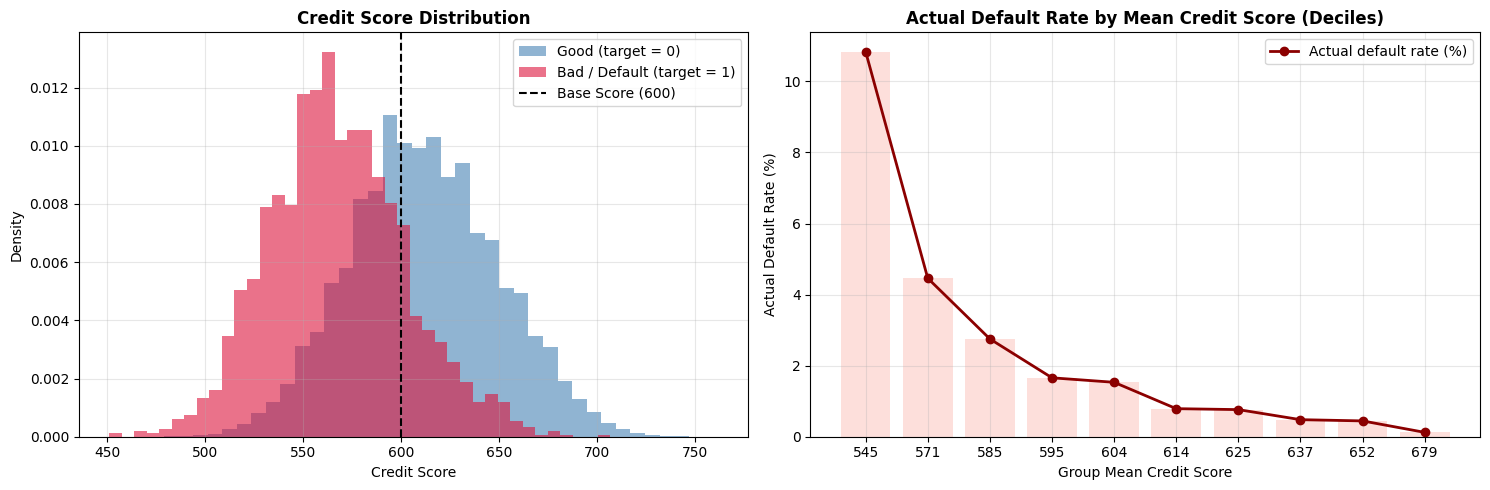

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

scores_good = scored_val_df.filter(pl.col("target") == 0)["credit_score"].to_numpy()
scores_bad  = scored_val_df.filter(pl.col("target") == 1)["credit_score"].to_numpy()

axes[0].hist(scores_good, bins=40, density=True, alpha=0.6, color="steelblue", label="Good (target = 0)")
axes[0].hist(scores_bad,  bins=40, density=True, alpha=0.6, color="crimson",   label="Bad / Default (target = 1)")
axes[0].axvline(BASE_POINTS, color="black", linestyle="--", label=f"Base Score ({BASE_POINTS})")
axes[0].set_title("Credit Score Distribution", fontsize=12, fontweight="bold")
axes[0].set_xlabel("Credit Score")
axes[0].set_ylabel("Density")
axes[0].legend()
axes[0].grid(alpha=0.3)


decile_df = (
    scored_val_df.with_columns(pl.col("credit_score").qcut(10, allow_duplicates=True).cast(pl.String).alias("score_bin"))
    .group_by("score_bin")
    .agg([pl.col("credit_score").mean().alias("mean_score"),
        (pl.col("target").mean() * 100).alias("bad_rate"),
        pl.len().alias("count")
    ]).sort("mean_score")
)

x_labels = [f"{int(s)}" for s in decile_df["mean_score"].to_list()]
bad_rates = decile_df["bad_rate"].to_list()

axes[1].plot(x_labels, bad_rates, marker="o", color="darkred", linewidth=2, label="Actual default rate (%)")
axes[1].bar(x_labels, bad_rates, alpha=0.25, color="salmon")
axes[1].set_title("Actual Default Rate by Mean Credit Score (Deciles)", fontsize=12, fontweight="bold")
axes[1].set_xlabel("Group Mean Credit Score")
axes[1].set_ylabel("Actual Default Rate (%)")
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

#Hyperparameter Tuning

In [ ]:
frac = 1 / 10
rng = np.random.default_rng(42)

y_arr = np.asarray(y_train)
keep = np.zeros(len(y_arr), dtype=bool)

for c in np.unique(y_arr):
    pos = np.where(y_arr == c)[0]
    n = int(round(len(pos) * frac))
    keep[rng.choice(pos, size=n, replace=False)] = True

X_tune = X_train.iloc[keep]
y_tune = y_train[keep]
y_tune.mean()

np.float64(0.033164857107200796)

In [ ]:
tscv = TimeSeriesSplit(n_splits=3)

logreg_params = {
    "clf__C": [0.001, 0.01, 0.1, 1, 10],
    "clf__penalty": ["l1", "l2"],
    "clf__solver": ["liblinear"]
}

logreg_grid_search = RandomizedSearchCV(
    estimator=models["Logistic Regression"],
    param_distributions=logreg_params,
    n_iter=10,
    scoring="roc_auc",
    cv=tscv,
    n_jobs=-1,
    verbose=2,
    random_state=42,
    refit=True
)

logreg_grid_search.fit(X_tune, y_tune)

print("Best Logistic Regression AUC:")
print(logreg_grid_search.best_score_)

print("\nBest parameters:")
print(logreg_grid_search.best_params_)

Fitting 3 folds for each of 10 candidates, totalling 30 fits


/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py:1271: UserWarning: 'n_jobs' > 1 does not have any effect when 'solver' is set to 'liblinear'. Got 'n_jobs' = 2.
  warnings.warn(


Best Logistic Regression AUC:
0.7507627102132134

Best parameters:
{'clf__solver': 'liblinear', 'clf__penalty': 'l1', 'clf__C': 0.01}


In [ ]:
for c in np.unique(y_arr):
    pos = np.where(y_arr == c)[0]
    n = int(round(len(pos) * 1 / 5))
    keep[rng.choice(pos, size=n, replace=False)] = True

X_tune2 = X_train.iloc[keep]
y_tune2 = y_train[keep]
y_tune2.mean()

np.float64(0.03326132705252742)

In [ ]:
# OPTUNA OBJECTIVE FUNCTION FOR LIGHTGBM
def lgb_objective(trial):
    params = {
        "n_estimators": 1000,
        "learning_rate": trial.suggest_float("learning_rate", 0.01, 0.1, log=True),
        "num_leaves": trial.suggest_int("num_leaves", 15, 127),
        "max_depth": trial.suggest_int("max_depth", 3, 10),
        "min_child_samples": trial.suggest_int("min_child_samples", 50, 500),
        "subsample": trial.suggest_float("subsample", 0.5, 1.0),
        "subsample_freq": 1,
        "colsample_bytree": trial.suggest_float("colsample_bytree", 0.5, 1.0),
        "reg_alpha": trial.suggest_float("reg_alpha", 1e-3, 10.0, log=True),
        "reg_lambda": trial.suggest_float("reg_lambda", 1e-3, 10.0, log=True),
        "subsample_for_bin": 200_000,
        "class_weight": "balanced",
        "random_state": 42,
        "n_jobs": -1,
        "verbose": -1
    }

    model = lgb.LGBMClassifier(**params)
    model.fit(
        X_tune2, y_tune2,
        eval_set=[(X_valid, y_valid)],
        eval_metric="auc",
        callbacks=[lgb.early_stopping(stopping_rounds=50, verbose=False)]
    )

    trial.set_user_attr("best_iteration", model.best_iteration_)
    preds = model.predict_proba(X_valid)[:, 1]
    return roc_auc_score(y_valid, preds)

# RUN OPTUNA OPTIMIZATION
lgb_study = optuna.create_study(direction="maximize", sampler=optuna.samplers.TPESampler(seed=42))
lgb_study.optimize(lgb_objective, n_trials=20, show_progress_bar=True)

# BUILD BEST LIGHTGBM MODEL
best_lgb_params = lgb_study.best_params
best_lgb_params.update({
    "n_estimators": lgb_study.best_trial.user_attrs["best_iteration"],
    "subsample_freq": 1,
    "subsample_for_bin": 200_000,
    "class_weight": "balanced",
    "random_state": 42,
    "n_jobs": -1,
    "verbose": -1
})
best_lgb_model = lgb.LGBMClassifier(**best_lgb_params)

print("Best LightGBM AUC:")
print(lgb_study.best_value)
print("\nBest parameters:")
print(best_lgb_params)

  0%|          | 0/20 [00:00<?, ?it/s]

Best LightGBM AUC:
0.8063135364856531

Best parameters:
{'learning_rate': 0.028580510658069373, 'num_leaves': 103, 'max_depth': 4, 'min_child_samples': 281, 'subsample': 0.7962072844310213, 'colsample_bytree': 0.5232252063599989, 'reg_alpha': 0.26926469100861794, 'reg_lambda': 0.004809461967501573, 'n_estimators': 776, 'subsample_freq': 1, 'subsample_for_bin': 200000, 'class_weight': 'balanced', 'random_state': 42, 'n_jobs': -1, 'verbose': -1}


In [ ]:
# INITIALIZE TUNED MODELS
tuned_models = {
    "Tuned Logistic Regression": logreg_grid_search.best_estimator_,
    "Tuned LightGBM": best_lgb_model
}

# FIT AND PREDICT WITH TUNED MODELS
tuned_val_preds = {}
for name, model in tuned_models.items():
    start = time.time()
    model.fit(X_train, y_train)
    tuned_val_preds[name] = model.predict_proba(X_valid)[:, 1]
    end = time.time() - start
    gc.collect()
    print(f"{name}: {round(end/60, 2)} minutes")

# EVALUATE TUNED MODELS ON VALIDATION SET
for name in tuned_models:
    prob_val  = tuned_val_preds[name]
    auc_val   = roc_auc_score(y_valid, prob_val)
    gini_val  = 2 * auc_val - 1
    stability = calc_gini_stability(valid_df, y_valid, prob_val)

    # THRESHOLD SELECTION
    prec_v, rec_v, thresh_v = precision_recall_curve(y_valid, prob_val)
    f1_v = 2 * (prec_v * rec_v) / (prec_v + rec_v + 1e-9)
    best_th = thresh_v[np.argmax(f1_v[:-1])] if len(thresh_v) > 0 else 0.5

    y_pred_val = (prob_val >= best_th).astype(int)

    eval_rows.append({
        "Model":          name,
        "Valid AUC":      round(auc_val, 4),
        "Valid Gini":     round(gini_val, 4),
        "Gini Stability": round(stability, 4),
        "Precision":      round(precision_score(y_valid, y_pred_val, zero_division=0), 4),
        "Recall":         round(recall_score(y_valid, y_pred_val, zero_division=0), 4),
        "F1-Score":       round(f1_score(y_valid, y_pred_val, zero_division=0), 4),
    })

results_df = pl.DataFrame(eval_rows).sort("Gini Stability", descending=True)
display(results_df)

/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py:1271: UserWarning: 'n_jobs' > 1 does not have any effect when 'solver' is set to 'liblinear'. Got 'n_jobs' = 2.
  warnings.warn(


Tuned Logistic Regression: 9.21 minutes
Tuned LightGBM: 3.32 minutes


Model,Valid AUC,Valid Gini,Gini Stability,Precision,Recall,F1-Score
str,f64,f64,f64,f64,f64,f64
"""Tuned LightGBM""",0.812,0.624,0.5835,0.1606,0.2723,0.202
"""LightGBM""",0.8082,0.6164,0.5707,0.1916,0.2155,0.2028
"""Random Forest""",0.7871,0.5742,0.538,0.1347,0.2789,0.1817
"""Tuned Logistic Regression""",0.7875,0.575,0.5237,0.1427,0.2475,0.1811
"""Logistic Regression""",0.7875,0.575,0.5235,0.1402,0.2541,0.1807
"""Decision Tree""",0.7511,0.5022,0.4518,0.1319,0.2004,0.1591


#Model Evaluation

In [ ]:
# PREDICT ON TEST SET WITH BEST LIGHTGBM
final_model = best_lgb_model

prob_val  = final_model.predict_proba(X_valid)[:, 1]
prob_test = final_model.predict_proba(X_test)[:, 1]

# THRESHOLD IS SELECTED ON VALIDATION SET ONLY, THEN APPLIED TO TEST
prec_v, rec_v, thresh_v = precision_recall_curve(y_valid, prob_val)
f1_v = 2 * prec_v * rec_v / (prec_v + rec_v + 1e-9)
best_th = thresh_v[np.argmax(f1_v[:-1])]


def evaluate(name, data_df, y_true, y_prob, threshold):
    auc = roc_auc_score(y_true, y_prob)
    y_pred = (y_prob >= threshold).astype(int)
    return {
        "Set":            name,
        "AUC":            round(auc, 4),
        "Gini":           round(2 * auc - 1, 4),
        "Gini Stability": round(calc_gini_stability(data_df, y_true, y_prob), 4),
        "Precision":      round(precision_score(y_true, y_pred, zero_division=0), 4),
        "Recall":         round(recall_score(y_true, y_pred, zero_division=0), 4),
        "F1-Score":       round(f1_score(y_true, y_pred, zero_division=0), 4),
    }


eval_df = pl.DataFrame([
    evaluate("Validation", valid_df, y_valid, prob_val,  best_th),
    evaluate("Test",       test_df,  y_test,  prob_test, best_th),
])
display(eval_df)

Set,AUC,Gini,Gini Stability,Precision,Recall,F1-Score
str,f64,f64,f64,f64,f64,f64
"""Validation""",0.812,0.624,0.5835,0.1606,0.2723,0.202
"""Test""",0.8275,0.6551,0.6284,0.1572,0.2697,0.1986


In [ ]:
# SCORING ON TEST SET
calibrated_pd_test = calibrate_pd(prob_test, prior_bad=prior_bad_train)
credit_scores_test = pd_to_credit_score(calibrated_pd_test)

scored_test_df = test_df.select(["case_id", "WEEK_NUM", "target"]).with_columns([
    pl.Series("raw_pd",        np.round(prob_test, 4)),
    pl.Series("calibrated_pd", np.round(calibrated_pd_test, 4)),
    pl.Series("credit_score",  credit_scores_test)
]).with_columns(
    pl.when(pl.col("credit_score") >= 660).then(pl.lit("A - Excellent"))
      .when(pl.col("credit_score") >= 620).then(pl.lit("B - Good"))
      .when(pl.col("credit_score") >= 580).then(pl.lit("C - Average"))
      .when(pl.col("credit_score") >= 540).then(pl.lit("D - Bad"))
      .otherwise(pl.lit("E - High risk"))
      .alias("risk_grade")
)
display(scored_test_df)

case_id,WEEK_NUM,target,raw_pd,calibrated_pd,credit_score,risk_grade
i64,i64,i64,f64,f64,i32,str
52875,78,0,0.6487,0.0596,567,"""D - Bad"""
52884,78,0,0.6384,0.0571,568,"""D - Bad"""
52975,78,0,0.4314,0.0254,592,"""C - Average"""
53062,78,0,0.3466,0.0179,603,"""C - Average"""
53064,78,0,0.1882,0.0079,627,"""B - Good"""
…,…,…,…,…,…,…
2703450,91,0,0.1874,0.0078,627,"""B - Good"""
2703451,91,0,0.3614,0.019,601,"""C - Average"""
2703452,91,0,0.4487,0.0272,590,"""C - Average"""


In [ ]:
total_defaults     = scored_test_df["target"].sum()
total_non_defaults = (scored_test_df["target"] == 0).sum()

risk_summary_test = (
    scored_test_df
    .group_by("risk_grade")
    .agg([
        pl.len().alias("num_of_cases"),
        pl.col("target").sum().alias("num_of_default"),
        (pl.col("target").sum() / total_defaults * 100).alias("ratio_of_total_defaults"),
        (pl.col("target") == 0).sum().alias("num_of_non_defaults"),
        ((pl.col("target") == 0).sum() / total_non_defaults * 100).alias("ratio_of_total_non_defaults"),
        (pl.col("target").mean() * 100).alias("bad_rate")
    ]).sort("risk_grade")
)
display(risk_summary_test)

risk_grade,num_of_cases,num_of_default,ratio_of_total_defaults,num_of_non_defaults,ratio_of_total_non_defaults,bad_rate
str,u32,i64,f64,u32,f64,f64
"""A - Excellent""",7696,9,0.279938,7687,5.17671,0.116944
"""B - Good""",43855,97,3.017107,43758,29.468254,0.221183
"""C - Average""",65840,833,25.909798,65007,43.778116,1.265188
"""D - Bad""",30226,1562,48.584759,28664,19.303397,5.167736
"""E - High risk""",4090,714,22.208398,3376,2.273523,17.457213


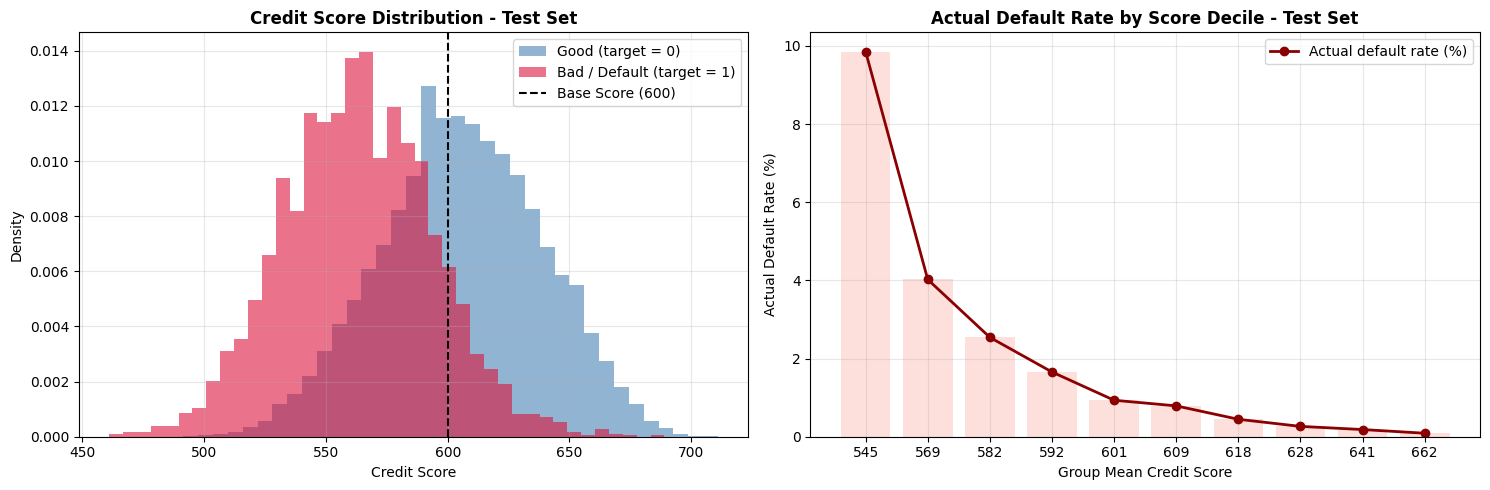

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

scores_good = scored_test_df.filter(pl.col("target") == 0)["credit_score"].to_numpy()
scores_bad  = scored_test_df.filter(pl.col("target") == 1)["credit_score"].to_numpy()

axes[0].hist(scores_good, bins=40, density=True, alpha=0.6, color="steelblue", label="Good (target = 0)")
axes[0].hist(scores_bad,  bins=40, density=True, alpha=0.6, color="crimson",   label="Bad / Default (target = 1)")
axes[0].axvline(BASE_POINTS, color="black", linestyle="--", label=f"Base Score ({BASE_POINTS})")
axes[0].set_title("Credit Score Distribution - Test Set", fontsize=12, fontweight="bold")
axes[0].set_xlabel("Credit Score")
axes[0].set_ylabel("Density")
axes[0].legend()
axes[0].grid(alpha=0.3)

decile_test = (scored_test_df
    .with_columns(pl.col("credit_score").qcut(10, allow_duplicates=True).cast(pl.String).alias("score_bin"))
    .group_by("score_bin")
    .agg([
        pl.col("credit_score").mean().alias("mean_score"),
        (pl.col("target").mean() * 100).alias("bad_rate"),
    ]).sort("mean_score")
)

x_labels  = [f"{int(s)}" for s in decile_test["mean_score"].to_list()]
bad_rates = decile_test["bad_rate"].to_list()

axes[1].bar(x_labels, bad_rates, alpha=0.25, color="salmon")
axes[1].plot(x_labels, bad_rates, marker="o", color="darkred", linewidth=2, label="Actual default rate (%)")
axes[1].set_title("Actual Default Rate by Score Decile - Test Set", fontsize=12, fontweight="bold")
axes[1].set_xlabel("Group Mean Credit Score")
axes[1].set_ylabel("Actual Default Rate (%)")
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

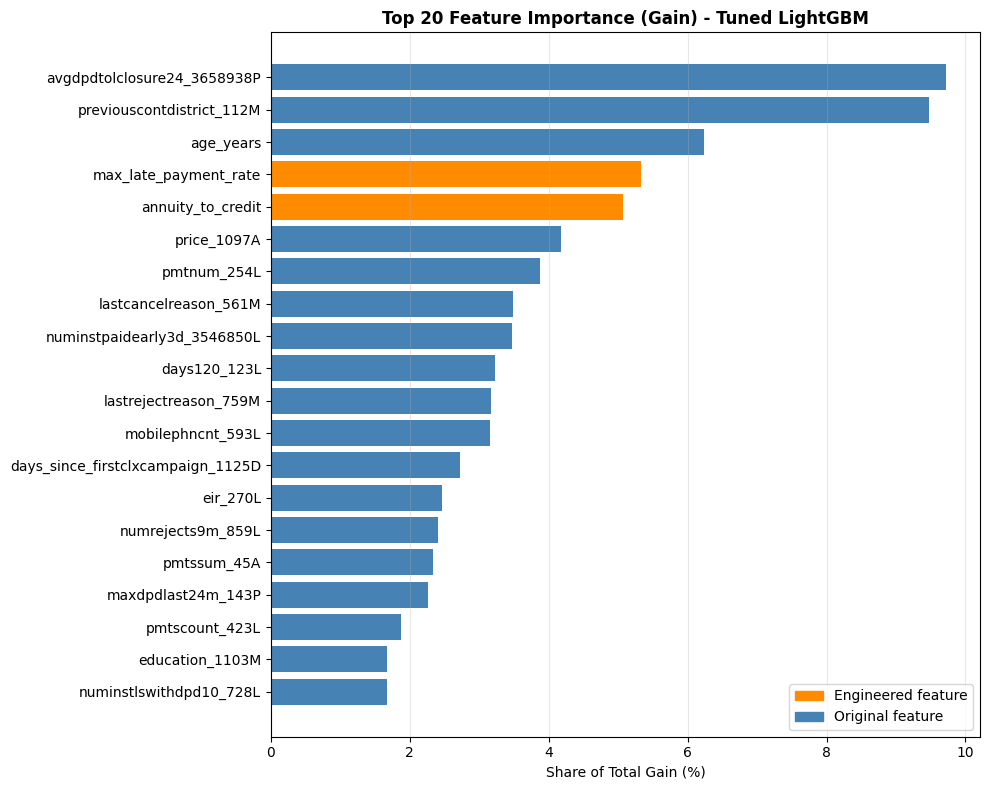

In [ ]:
# FEATURE IMPORTANCE BY GAIN
booster = final_model.booster_

importance_df = (pl.DataFrame({
        "Feature": booster.feature_name(),
        "Gain":    booster.feature_importance(importance_type="gain"),
    }).with_columns((pl.col("Gain") / pl.col("Gain").sum() * 100).alias("Gain_pct")).sort("Gain", descending=True)
)

top20 = importance_df.head(20).sort("Gain_pct")
colors = ["darkorange" if f in NEW_FEATURES else "steelblue" for f in top20["Feature"]]

plt.figure(figsize=(10, 8))
plt.barh(top20["Feature"], top20["Gain_pct"], color=colors)
plt.title("Top 20 Feature Importance (Gain) - Tuned LightGBM", fontsize=12, fontweight="bold")
plt.xlabel("Share of Total Gain (%)")
plt.grid(axis="x", alpha=0.3)

# LEGEND: ENGINEERED VS ORIGINAL FEATURES
plt.legend(handles=[Patch(color="darkorange", label="Engineered feature"),
                    Patch(color="steelblue",  label="Original feature")], loc="lower right")
plt.tight_layout()
plt.show()

#